In [1]:
#import some basic classes
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.util as cutil
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats

#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/AtmBlockPy/lib")
import BlockPlots as BP
import BlockTools as BT

In [2]:
%cd /Users/michelefilippucci/Data/ERA5/geop
#!cdo selmon,6,7,8 ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_jja_1940-2023.nc
!ls

/Users/michelefilippucci/Data/ERA5/geop
ERA5_2.5x2.5_zg500_daily_1940-2024.nc
ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_monthly_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_monthly_jja_1940-2023_detrended.nc


In [3]:
g = 9.80665  
  
#locations
reanalysis = "ERA5_northem_2.5x2.5_zg500_monthly_jja_1940-2023_detrended.nc"
output = "/Users/michelefilippucci/PLOTS/pres_exeter/geop_climatology.png"
label = "jja"

<xarray.DataArray 'zg_an' ()>
array(-13.2) <xarray.DataArray 'zg_an' ()>
array(23.46)


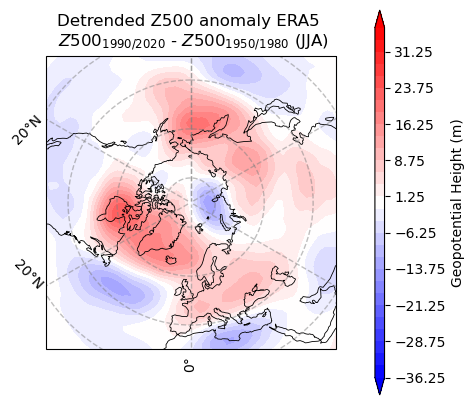

In [4]:
ds = xr.load_dataset(reanalysis)
zg_stat = np.mean(ds["zg"].loc["1950-06-01T09:00:00":"1980-08-31T09:00:00"], axis = 0)/9.81
zg_stat.name = "zg"
zg_stat2 = np.mean(ds["zg"].loc["1990-06-01T09:00:00":"2020-08-31T09:00:00"], axis = 0)/9.81
zg_stat2.name = "zg"
diff = zg_stat2 - zg_stat
diff.name = "zg_an"
print(np.amin(diff),np.amax(diff))

lon = ds['lon'].values
lon = np.append(lon,180)
lat = ds['lat']
diff = cutil.add_cyclic_point(diff)

fig,ax = plt.subplots(nrows=1,ncols=1,figsize=(5,5),subplot_kw={'projection':ccrs.AzimuthalEquidistant(central_latitude=90)})
extent =[-180,180,30,90]
ax.set_extent(extent, ccrs.PlateCarree())
ax.coastlines(linewidth = 0.6)
gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                linewidth=1, 
                color='gray', 
                alpha=0.5, 
                linestyle='--')

gl.top_labels=False
gl.right_labels=False
cont = ax.contourf(lon,lat,diff,
                      np.arange(-36.25,+36.5,2.5),
                      extent=[0,90,-180,180],
                      extend = 'both',
                      transform = ccrs.PlateCarree(),
                      cmap = "bwr")
ax.set_title('Detrended Z500 anomaly ERA5 \n $Z500_{1990/2020}$ - $Z500_{1950/1980}$ (JJA)')

cbar = plt.colorbar(cont, orientation='vertical',label="Geopotential Height (m)",pad=0.1, aspect=40)

plt.show()
fig.savefig(output,dpi=300)

# 